# Lab 13.2: Explaining a Delay Forecast

Chapter 13 of *Explainable AI in Practice*. Run the cells in order; nothing needs to be edited. The first run downloads one month of US flight data (about 35 MB) from the Bureau of Transportation Statistics and builds the features (about 30 seconds).

In [1]:
import os, pathlib, tempfile, zipfile, urllib.request, warnings
import numpy as np, pandas as pd, shap
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")
CACHE = pathlib.Path(os.environ.get("XAI_DATA", pathlib.Path(tempfile.gettempdir()) / "xai-book-data"))
CACHE.mkdir(parents=True, exist_ok=True)
URL = "https://transtats.bts.gov/PREZIP/On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2024_7.zip"
if not list(CACHE.glob("On_Time_Reporting*2024_7.csv")):
    z = CACHE / "bts_2024_7.zip"
    if not z.exists():
        urllib.request.urlretrieve(URL, z)
    with zipfile.ZipFile(z) as f:
        f.extractall(CACHE)
csv = next(CACHE.glob("On_Time_Reporting*2024_7.csv"))
cols = ["DayofMonth", "DayOfWeek", "Reporting_Airline", "Tail_Number", "Origin", "Dest", "CRSDepTime", "DepDelay",
        "DepDel15", "CRSArrTime", "Cancelled", "Diverted", "CRSElapsedTime", "Distance"]
raw = pd.read_csv(csv, usecols=cols, dtype={"Tail_Number": str})
print("flights:", len(raw), " cancelled:", int(raw.Cancelled.sum()))

flights: 634613  cancelled: 18372


## 1. Leak-free features

We predict at time p = scheduled departure minus 120 minutes. A departure scheduled before p that has not left yet is known only to be *at least* p minus its scheduled time late; we use that lower bound. The inbound aircraft's departure time is converted to this airport's clock with its scheduled flight time, so time zones do not leak in.

In [2]:
df = raw.copy()
mins = lambda h: (h // 100) * 60 + h % 100
day0 = (df.DayofMonth - 1) * 1440
dep = mins(df.CRSDepTime); arr = mins(df.CRSArrTime)
df["s_dep"] = day0 + dep
df["s_arr"] = day0 + arr + np.where(arr < dep, 1440, 0)
df["a_dep"] = df.s_dep + df.DepDelay
df["p"] = df.s_dep - 120
df = df.sort_values("s_dep").reset_index(drop=True)
top = df.Origin.value_counts().index[:30]
for k in (1, 2, 3):
    df[f"apt_lag{k}"] = np.nan
df["apt_n"] = np.nan
ok = df.Cancelled == 0
for o, g in df[df.Origin.isin(top)].groupby("Origin"):
    src = g[ok.loc[g.index]]
    s = src.s_dep.to_numpy(); a = src.a_dep.to_numpy(); dd = np.clip(src.DepDelay.to_numpy(), 0, None)
    for day in range(1, 32):
        tgt = g[g.DayofMonth == day]
        if tgt.empty:
            continue
        p = tgt.p.to_numpy()[:, None]
        c = np.where((s >= p.min() - 180) & (s < p.max()))[0]
        ss, aa, d2 = s[c][None, :], a[c][None, :], dd[c][None, :]
        known = np.where(aa <= p, d2, p - ss)
        for k in (1, 2, 3):
            w = (ss >= p - 60 * k) & (ss < p - 60 * (k - 1))
            nk = w.sum(1)
            df.loc[tgt.index, f"apt_lag{k}"] = np.where(nk > 0, (known * w).sum(1) / np.maximum(nk, 1), np.nan)
            if k == 1:
                df.loc[tgt.index, "apt_n"] = nk
t = df[df.Tail_Number.notna()].sort_values(["Tail_Number", "s_dep"])
prev = t.groupby("Tail_Number").shift(1)
valid = (prev.Dest == t.Origin) & (t.s_dep - prev.s_arr).between(0, 360)
in_s = prev.s_arr - prev.CRSElapsedTime
in_a = in_s + prev.DepDelay
known_in = np.where(prev.Cancelled == 1, np.nan, np.where(in_a <= t.p, prev.DepDelay, np.where(in_s < t.p, t.p - in_s, np.nan)))
df.loc[t.index, "in_delay"] = np.where(valid, known_in, np.nan)
df.loc[t.index, "in_status"] = np.where(~valid, 0, np.where(in_a <= t.p, 2, np.where(in_s < t.p, 1, 3)))
df.loc[t.index, "turn_slack"] = np.where(valid, t.s_dep - prev.s_arr, np.nan)
df["in_status"] = df.in_status.fillna(0)
df["hour"] = (dep // 60).astype(float)
df["log_apt_size"] = np.log(df.groupby("Origin").Origin.transform("size") / 31)
df["carrier"] = df.Reporting_Airline.astype("category").cat.codes
d = df[(df.Cancelled == 0) & (df.Diverted == 0) & df.Origin.isin(top) & df.DepDel15.notna()].copy()
print("Checkpoint 1: modeling rows", len(d), " share delayed 15+ min:", round(d.DepDel15.mean(), 3))

Checkpoint 1: modeling rows 394541  share delayed 15+ min: 0.32


## 2. Train on July 1-14, test on July 15-31

In [3]:
F = ["hour", "DayOfWeek", "carrier", "Distance", "log_apt_size", "apt_lag1", "apt_lag2", "apt_lag3", "apt_n",
     "in_delay", "in_status", "turn_slack"]
G = {"schedule and carrier": F[:5], "airport, last 3 hours": F[5:9], "inbound aircraft": F[9:]}
tr = d[d.DayofMonth <= 14]; te = d[d.DayofMonth >= 15].copy()
def fit(X, y, seed=0):
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, max_leaf_nodes=31,
                                          categorical_features=[2], random_state=seed).fit(X, y)
m = fit(tr[F], tr.DepDel15)
te["p"] = m.predict_proba(te[F])[:, 1]
print("Checkpoint 2: test AUC", round(roc_auc_score(te.DepDel15, te.p), 3))
for g, c in G.items():
    keep = [f for f in F if f not in c]
    mm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=0).fit(tr[keep], tr.DepDel15)
    print(f"   AUC without {g:>22}:", round(roc_auc_score(te.DepDel15, mm.predict_proba(te[keep])[:, 1]), 3))

Checkpoint 2: test AUC 0.839


   AUC without   schedule and carrier: 0.83


   AUC without  airport, last 3 hours: 0.797


   AUC without       inbound aircraft: 0.729


## 3. SHAP values for features and for groups

In [4]:
S = te.sample(3000, random_state=1)
ex = shap.TreeExplainer(m)
sv = ex.shap_values(S[F])
print(pd.Series(np.abs(sv).mean(0), F).sort_values(ascending=False).round(3).to_string())
print("Checkpoint 3: mean |group SHAP|",
      {g: round(float(np.abs(sv[:, [F.index(x) for x in c]].sum(1)).mean()), 2) for g, c in G.items()})

in_delay        0.884
turn_slack      0.382
apt_lag1        0.327
apt_lag2        0.224
in_status       0.214
apt_lag3        0.149
carrier         0.134
log_apt_size    0.078
hour            0.069
Distance        0.064
apt_n           0.057
DayOfWeek       0.055
Checkpoint 3: mean |group SHAP| {'schedule and carrier': 0.18, 'airport, last 3 hours': 0.65, 'inbound aircraft': 1.13}


## 4. Stability: which hour mattered most?

We retrain on five bootstrap samples and compare, flight by flight, which of the three airport windows gets the largest attribution, and how well the group total agrees.

In [5]:
print("correlation of the three hourly windows:")
print(S[["apt_lag1", "apt_lag2", "apt_lag3"]].corr().round(2).to_string())
rng = np.random.default_rng(0)
lag_idx = [F.index(f) for f in ["apt_lag1", "apt_lag2", "apt_lag3"]]
grp_idx = [F.index(c) for c in G["airport, last 3 hours"]]
runs = []
for b in range(5):
    idx = rng.choice(len(tr), len(tr), replace=True)
    s_b = shap.TreeExplainer(fit(tr[F].iloc[idx], tr.DepDel15.iloc[idx], b)).shap_values(S[F])
    runs.append(s_b)
for b in range(1, 5):
    agree = (np.abs(runs[b][:, lag_idx]).argmax(1) == np.abs(runs[0][:, lag_idx]).argmax(1)).mean()
    corr = np.corrcoef(runs[b][:, grp_idx].sum(1), runs[0][:, grp_idx].sum(1))[0, 1]
    print(f"Checkpoint 4: run {b} vs run 0: top-hour agreement {agree:.2f}, group correlation {corr:.3f}")

correlation of the three hourly windows:
          apt_lag1  apt_lag2  apt_lag3
apt_lag1      1.00      0.72      0.70
apt_lag2      0.72      1.00      0.78
apt_lag3      0.70      0.78      1.00


Checkpoint 4: run 1 vs run 0: top-hour agreement 0.73, group correlation 0.973
Checkpoint 4: run 2 vs run 0: top-hour agreement 0.79, group correlation 0.976
Checkpoint 4: run 3 vs run 0: top-hour agreement 0.75, group correlation 0.966
Checkpoint 4: run 4 vs run 0: top-hour agreement 0.77, group correlation 0.971


## 5. Explanations during the July 19, 2024 outage

In [6]:
rows = []
for day, g in te.groupby("DayofMonth"):
    for dl in (True, False):
        s = g[(g.Reporting_Airline == "DL") == dl]
        s = s.sample(min(len(s), 1500), random_state=0)
        v = ex.shap_values(s[F])
        r = {"day": day, "Delta": dl, "actual": s.DepDel15.mean(), "predicted": s.p.mean()}
        for k, c in G.items():
            r[k] = v[:, [F.index(x) for x in c]].sum(1).mean()
        rows.append(r)
R = pd.DataFrame(rows)
print("Checkpoint 5 (Delta flights):")
print(R[R.Delta].drop(columns="Delta").round(3).to_string(index=False))
print("Delta share late in training weeks:", round(tr[tr.Reporting_Airline == "DL"].DepDel15.mean(), 3),
      " others:", round(tr[tr.Reporting_Airline != "DL"].DepDel15.mean(), 3))
print("Delta cancellations July 19-23 (all airports):",
      int(raw[(raw.Reporting_Airline == "DL") & raw.DayofMonth.between(19, 23)].Cancelled.sum()))

Checkpoint 5 (Delta flights):
 day  actual  predicted  schedule and carrier  airport, last 3 hours  inbound aircraft
  15   0.306      0.275                -0.228                  0.140            -0.107
  16   0.247      0.223                -0.260                  0.053            -0.279
  17   0.289      0.235                -0.141                  0.030            -0.254
  18   0.351      0.271                -0.140                  0.157             0.005
  19   0.933      0.610                -0.195                  0.681             1.874
  20   0.823      0.523                -0.167                  0.516             1.125
  21   0.835      0.542                -0.224                  0.425             1.279
  22   0.795      0.559                -0.213                  0.555             1.217
  23   0.654      0.473                -0.230                  0.488             0.917
  24   0.404      0.323                -0.139                  0.194             0.197
  25   0.247 

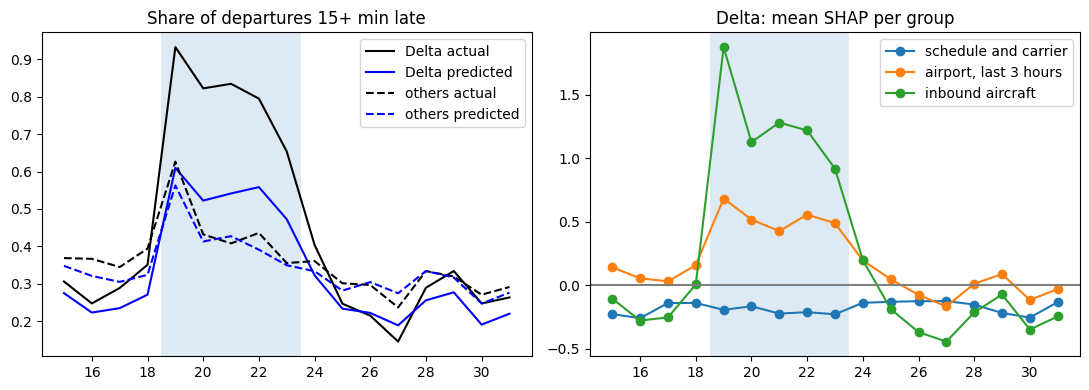

In [7]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for dl, ls in ((True, "-"), (False, "--")):
    q = R[R.Delta == dl]
    axs[0].plot(q.day, q.actual, "k" + ls, label=("Delta" if dl else "others") + " actual")
    axs[0].plot(q.day, q.predicted, "b" + ls, label=("Delta" if dl else "others") + " predicted")
axs[0].axvspan(18.5, 23.5, alpha=0.15); axs[0].legend(); axs[0].set_title("Share of departures 15+ min late")
for k in G:
    axs[1].plot(R[R.Delta].day, R[R.Delta][k], marker="o", label=k)
axs[1].axhline(0, color="gray"); axs[1].axvspan(18.5, 23.5, alpha=0.15); axs[1].legend(); axs[1].set_title("Delta: mean SHAP per group")
plt.tight_layout(); plt.show()

## Your turn

Write the one-page explanation report described in the README. Use the group level for anything a controller will read, and say what the model cannot see.